In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt
import gc
import cv2
import os
from tensorflow.keras.utils import to_categorical
import tensorflow as tf
from tensorflow.keras.layers import Input,GlobalAveragePooling2D,Dense, Flatten,Activation, BatchNormalization, Dropout, Lambda, Conv2D, Conv2DTranspose, MaxPooling2D, concatenate

from kaggle_datasets import KaggleDatasets

from tensorflow.keras.applications.densenet import DenseNet121
from sklearn.model_selection import StratifiedShuffleSplit,train_test_split,GridSearchCV,cross_val_score, cross_val_predict

from tensorflow.keras import backend as K

/opt/conda/lib/python3.10/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.23.5
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


In [2]:
images=[]
masks=[]

path_img="/kaggle/input/chest-xray-masks-and-labels/Lung Segmentation/CXR_png"
path_mask="/kaggle/input/chest-xray-masks-and-labels/Lung Segmentation/masks"

In [3]:
df=pd.read_csv('/kaggle/input/tfrecords-szcxmc-w5/segm_classification.csv')
                
x=df["img_name"]
y=df["category"]
z=df["mask"]

In [4]:
df

,Unnamed: 0,img_name,category,target,mask
0,0,CHNCXR_0120_0.png,normal,[1 0],CHNCXR_0120_0_mask.png
1,1,CHNCXR_0548_1.png,tb,[0 1],CHNCXR_0548_1_mask.png
2,2,CHNCXR_0119_0.png,normal,[1 0],CHNCXR_0119_0_mask.png
3,3,CHNCXR_0403_1.png,tb,[0 1],CHNCXR_0403_1_mask.png
4,4,CHNCXR_0368_1.png,tb,[0 1],CHNCXR_0368_1_mask.png
...,...,...,...,...,...
561,561,CHNCXR_0517_1.png,tb,[0 1],CHNCXR_0517_1_mask.png
562,562,CHNCXR_0410_1.png,tb,[0 1],CHNCXR_0410_1_mask.png
563,563,CHNCXR_0606_1.png,tb,[0 1],CHNCXR_0606_1_mask.png
564,564,CHNCXR_0604_1.png,tb,[0 1],CHNCXR_0604_1_mask.png


In [5]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train_label,y_test_label, y_train_mask,y_test_mask = train_test_split(x,y,z, test_size=0.2, random_state=18)
df_train = pd.DataFrame(columns=['image_names','category','mask'])
df_train["image_names"]=X_train
df_train["category"]=y_train_label
df_train["mask"] = y_test_label


df_val = pd.DataFrame(columns=['image_names','category','mask'])
df_val["image_names"]=X_test
df_val["category"]=y_test_label
df_val["mask"] = y_test_mask

In [6]:
a= y_train_label
v=lambda x:np.where(x=='tb',1,0)
a=v(a)

b=to_categorical(a,dtype='int')


In [7]:
c= y_test_label
d=lambda x:np.where(x=='tb',1,0)
c=d(c)

d=to_categorical(c,dtype='int')

In [8]:
for imagename in tqdm(df_train.loc[:,"image_names"]):
    
    image = cv2.imread(path_img+"/"+ imagename)
    image2=cv2.imread(path_mask+"/"+ imagename.split(".")[0]+"_mask.png")
    #image=cv2.cvtColor(image,cv2.COLOR_BGR2GRAY)
    
   
    #image2=cv2.cvtColor(image2,cv2.COLOR_BGR2GRAY)
    image=cv2.resize(image,(224,224))[:,:,:3]/255
    image2=cv2.resize(image2,(224,224))[:,:,0]/255
    
        
    
    images.append(image)
    masks.append(image2)

  0%|          | 0/452 [00:00<?, ?it/s]

In [9]:
x_train = np.asarray(images)

y_train = (b,np.asarray(masks))
masks = np.asarray(masks)

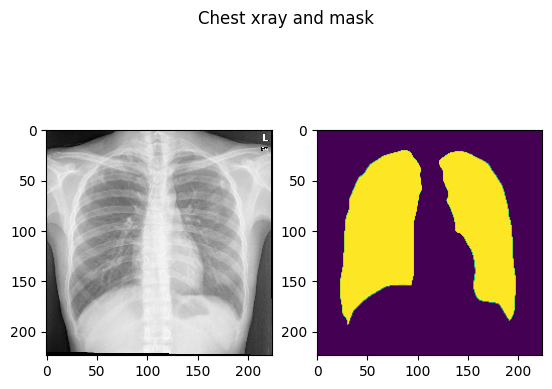

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('Chest xray and mask')
ax1.imshow(x_train[0])
ax2.imshow(y_train[1][0])

In [11]:
val_img=[]
val_mask=[]

In [12]:
for imagename in tqdm(df_val.loc[:,"image_names"]):
    
    image = cv2.imread(path_img+"/"+ imagename)
    image2=cv2.imread(path_mask+"/"+ imagename.split(".")[0]+"_mask.png")
   
    image=cv2.resize(image,(224,224))[:,:,:3]/255
   
  
    image2=cv2.resize(image2,(224,224))[:,:,0]/255
    
    
    val_img.append(image)
    val_mask.append(image2)

  0%|          | 0/114 [00:00<?, ?it/s]

In [13]:
x_val = np.asarray(val_img)[:95]
y_val = (d[:95])
val_d = d[:95]
val_masks = np.asarray(val_mask[:95])


x_test  = np.asarray(val_img)[95:]                     
y_test = (d[95:])

In [14]:
grados = -10
centro_rotacion = (224//2, 224//2) # centro de la imagen
matriz_rotacion = cv2.getRotationMatrix2D(centro_rotacion, grados, 1.0)

num_imagenes = x_train.shape[0]
imagenes_rotadas = np.empty_like(x_train)
x_train_aug = []
masks_aug =[]
labels = b


for i in range(num_imagenes):
    img = x_train[i]
    img_rotada = cv2.warpAffine(img, matriz_rotacion, (224, 224))
    x_train_aug.append(img_rotada)
    
    



# for imagen in x_train:
#     imagen_aumentada = seq.augment_image(imagen)
#     x_train_aug.append(imagen_aumentada)
    
for j in range(num_imagenes):
    img_mask = masks[j]
    img_mask_rotada = cv2.warpAffine(img_mask, matriz_rotacion, (224, 224))
    masks_aug.append(img_mask_rotada)
    
x_train = np.concatenate((x_train, x_train_aug))
masks = np.concatenate((masks, masks_aug))
b = np.concatenate((b, labels))

In [15]:
print(x_train.shape,masks.shape, b.shape)

(904, 224, 224, 3) (904, 224, 224) (904, 2)


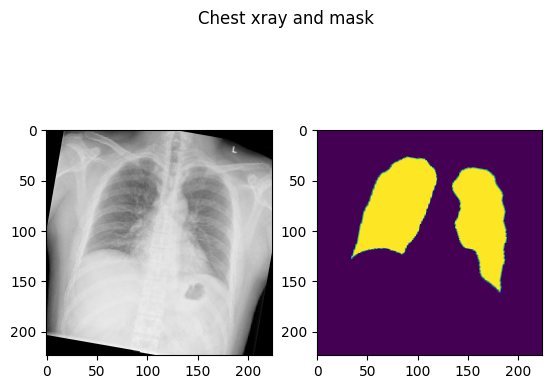

In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('Chest xray and mask')
ax1.imshow(x_train[600])
ax2.imshow(masks[600])

### Architecture

### Multi loss layer

In [17]:
model= tf.keras.applications.mobilenet.MobileNet(input_shape=None,alpha=1.0,
                                                 depth_multiplier=1,
                                                 dropout=0.001,
                                                 include_top=True,
                                                 weights='imagenet',
                                                 input_tensor=None,
                                                 pooling=None,
                                                 classes=1000,
                                                 classifier_activation='softmax')

17225924/17225924 [==============================] - 0s 0us/step


In [18]:
conv4  = model.get_layer('conv_pw_11_relu').output
conv5 = Conv2DTranspose(512, (2, 2), strides=(2, 2), padding='valid', name ='capa_1')(conv4)

conv6 = Conv2D(512, (3, 3), activation='relu', padding='same', name ='capa_2')(conv5)
conv6 = Conv2D(512, (3, 3), activation='relu', padding='same', name ='capa_3')(conv6)
conv6 = Conv2DTranspose(256, (2, 2), strides=(2, 2), padding='same', name ='capa_4')(conv6)


conv7 = Conv2D(256, (3, 3), activation='relu', padding='same', name ='capa_5')(conv6)
conv7 = Conv2D(256, (3, 3), activation='relu', padding='same', name ='capa_6')(conv7)
conv7 = Conv2DTranspose(256, (2, 2), strides=(2, 2), padding='same', name ='capa_7')(conv7)


conv8 = Conv2D(64, (3, 3), activation='relu', padding='same', name ='capa_8')(conv7)
conv8 = Conv2D(64, (3, 3), activation='relu', padding='same', name ='capa1_9')(conv8)
conv8 = Conv2DTranspose(32, (2, 2), strides=(2, 2), padding='same', name ='capa_10')(conv8)


conv9 = Conv2D(32, (3, 3), activation='relu', padding='same', name ='capa_11')(conv8)
conv9 = Conv2D(32, (3, 3), activation='relu', padding='same', name ='capa_12')(conv9)


conv10 = Conv2D(1, (1, 1), activation='sigmoid', name = 'segm')(conv9)
    
x = model.get_layer('predictions').output
x = Dense(512, activation='relu')(x)
x = Dropout(0.5,name = 'dropout_1')(x)
outputs = Dense(2, activation ='softmax',name = 'classification')(x)
    

In [19]:
conv4_img  = model.get_layer('conv_pw_11_relu').output
conv5_img  = Conv2DTranspose(512, (2, 2), strides=(2, 2), padding='valid', name ='capa_1_img')(conv4_img)

conv6_img  = Conv2D(512, (3, 3), activation='relu', padding='same', name ='capa_2_img')(conv5_img)
conv6_img  = Conv2D(512, (3, 3), activation='relu', padding='same', name ='capa_3_img')(conv6_img)
conv6_img  = Conv2DTranspose(256, (2, 2), strides=(2, 2), padding='same', name ='capa_4_img')(conv6_img)


conv7_img  = Conv2D(256, (3, 3), activation='relu', padding='same', name ='capa_5_img')(conv6_img)
conv7_img  = Conv2D(256, (3, 3), activation='relu', padding='same', name ='capa_6_img')(conv7_img)
conv7_img  = Conv2DTranspose(256, (2, 2), strides=(2, 2), padding='same', name ='capa_7_img')(conv7_img)


conv8_img  = Conv2D(64, (3, 3), activation='relu', padding='same', name ='capa_8_img')(conv7_img)
conv8_img  = Conv2D(64, (3, 3), activation='relu', padding='same', name ='capa_9_img')(conv8_img)
conv8_img  = Conv2DTranspose(32, (2, 2), strides=(2, 2), padding='same', name ='capa_10_img')(conv8_img)


conv9_img  = Conv2D(32, (3, 3), activation='relu', padding='same', name ='capa_11_img')(conv8_img)
conv9_img  = Conv2D(32, (3, 3), activation='relu', padding='same', name ='capa_12_img')(conv9_img)


conv10_img  = Conv2D(3, (1, 1), activation='relu', name = 'segm_img')(conv9_img)

In [20]:
model_hibrid = tf.keras.Model(inputs=model.input, outputs =[outputs])


In [21]:
model_hibrid.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 conv1 (Conv2D)              (None, 112, 112, 32)      864       
                                                                 
... [209 lines of log output omitted for readability] ...
                                                                 
 dense (Dense)               (None, 512)               512512    
                                                                 
 dropout_1 (Dropout)         (None, 512)               0         
                                                                 
 classification (Dense)      (None, 2)                 1026      
                                                                 
Total params: 4,767,402
Trainable params: 4,745,514
Non-trainable par

In [22]:
def dice_coef(y_true, y_pred, smooth = 1.):
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (K.sum(y_true_f) + K.sum(y_pred_f) + smooth)



def dice_coef_loss(y_true, y_pred):
    return -dice_coef(y_true, y_pred)


def jaccard(y_true, y_pred, smooth=100):
    intersection = tf.reduce_sum(y_true * y_pred, axis=(1,2))
    sum_ = tf.reduce_sum(y_true + y_pred, axis=(1,2))
    jac = (intersection + smooth) / (sum_ - intersection + smooth)
  
    return tf.reduce_mean(jac)

In [23]:
from keras.layers import Input, Dense, Lambda, Layer
from keras.layers import Input, Dense, Lambda, Layer
from keras.initializers import Constant
from keras.models import Model
from keras import backend as K
from keras.losses import binary_crossentropy 


class CustomMultiLossLayer(Layer):
    def __init__(self, nb_outputs=3,**kwargs):
        self.is_placeholder = True
        self.nb_outputs = nb_outputs
        self.num_classes = 1  # Number of classes for segmentation
        nb_outputs =3 
        super(CustomMultiLossLayer, self).__init__(**kwargs)
        
    def build(self, input_shape=None):
                # initialise log_vars
        self.log_vars = []
        for i in range(self.nb_outputs):
            self.log_vars += [self.add_weight(name='log_var' + str(i), shape=(1,),
                                              initializer=Constant(0.), trainable=True)]
        super(CustomMultiLossLayer, self).build(input_shape)
 

    def multi_loss(self, y_true, y_pred):
        flatten_layer = tf.keras.layers.Flatten()
        # Apply the Flatten layer to the input tensor
        
        y_true[0] = flatten_layer(y_true[0])
        y_pred[0] = flatten_layer(y_pred[0])
        
        y_true[1] = flatten_layer(y_true[1])
        y_pred[1] = flatten_layer(y_pred[1])
        
        y_true[2] = flatten_layer(y_true[2])
        y_pred[2] = flatten_layer(y_pred[2])

        loss = 0
        precision1 = tf.exp(-self.log_vars[0])
        loss = K.sum(precision1 * (y_true[0] - y_pred[0]) ** 2. + self.log_vars[0], -1)

        precision2 = tf.exp(-self.log_vars[1])
        loss += K.sum(precision2 * (y_true[1] - y_pred[1]) ** 2. + self.log_vars[1], -1)
        
        precision3 = tf.exp(-self.log_vars[2])
        loss += K.sum(precision2 * (y_true[2] - y_pred[2]) ** 2. + self.log_vars[2], -1)

        loss = K.mean(loss)

        
        return loss

    def call(self, inputs):
        y_true = inputs[:3]
        y_pred = inputs[3:]
        # Expand the shape of the first tensor to match the shape of the second tensor
        inputs[0] = K.expand_dims(inputs[0], axis=1)
        inputs[0] = K.expand_dims(inputs[0], axis=1)
        inputs[0] = K.tile(inputs[0], [1, 224, 224, 1])

        inputs[3] = K.expand_dims(inputs[3], axis=1)
        inputs[3] = K.expand_dims(inputs[3], axis=1)
        inputs[3] = K.tile(inputs[3], [1, 224, 224, 1])
        loss = self.multi_loss(y_true, y_pred)
        
        self.add_loss(loss, inputs=inputs)
#
        
        
        # We won't actually use the output.
        return K.concatenate(inputs,-1)

In [24]:
# inp = Input(shape=(224,224,3,), name='inp')
# y1_pred, y2_pred,y3_pred = model_hibrid(inp)
# y1_true = Input(shape=(2,), name='y1_true')
# y2_true = Input(shape=(224,224,1,), name='y2_true')
# y3_true = Input(shape=(224,224,3,), name='y3_true')
# out = CustomMultiLossLayer()([y1_true, y2_true,y3_true, y1_pred, y2_pred,y3_pred])
# Model2 =  Model([inp, y1_true, y2_true,y3_true], out)

In [25]:
# Model2.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss=None)
# Model2.summary()

In [26]:
# hist = Model2.fit([x_train,b], batch_size=16,steps_per_epoch=128,epochs=80)


In [27]:
# import pylab
# %matplotlib inline


# pylab.plot(hist.history['loss'])

In [28]:
# import math

# img_weights   =  Model2.layers[-1].log_vars[2]
# seg_weights   =  Model2.layers[-1].log_vars[1]
# class_weights =  Model2.layers[-1].log_vars[0]


# print(math.exp(img_weights) ** 0.5 )
# img_weights = math.exp(img_weights) ** 0.5 

# print(math.exp(seg_weights) ** 0.5 )
# seg_weights = math.exp(seg_weights) ** 0.5 

# print(math.exp(class_weights) ** 0.5 )
# class_weights = math.exp(class_weights) ** 0.5

In [29]:
# tf.keras.backend.clear_session()

In [30]:
#lossWeights = {'classification':class_weights, 'segm': seg_weights, 'segm_img': img_weights}

model_hibrid.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                   loss={'classification':['binary_crossentropy'],
                           },
                   #loss_weights=lossWeights,
                   metrics={'classification':['accuracy', tf.keras.metrics.AUC(multi_label=True),
                                              tf.keras.metrics.SpecificityAtSensitivity(0.9)]})
#                             'segm': [dice_coef, jaccard,'binary_accuracy',
#                                                tf.keras.metrics.Recall()],
#                             'segm_img': tf.keras.metrics.MeanSquaredError()})

In [31]:
#history = model_hibrid.fit(x=x_train,y=b,validation_data=(x_val,y_val),batch_size=8,steps_per_epoch=256,epochs=70)

In [32]:
# import pylab
# %matplotlib inline


# pylab.plot(history.history['loss'])

In [33]:
model_hibrid.save('MobileNet_class.h5')


In [34]:
from tensorflow.keras.models import load_model


In [45]:
path7 = '/kaggle/input/modelos-paper2/modelos/One task_segm/Mobilenet_segm.h5'
path8 = '/kaggle/input/modelos-paper2/modelos/Models_multi_2/mobilenet_multi_out_2_task.h5'
path9 = '/kaggle/input/modelos-paper2/modelos/Models_multi_3/mobilenet_multi_out_3_task.h5'
model_hibrid  =  load_model(path8,custom_objects = {'dice_coef':dice_coef, 'jaccard':jaccard})


In [46]:
model_hibrid.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 224, 224, 3  0           []                               
                                )]                                                                
                                                                                                  
 conv1 (Conv2D)                 (None, 112, 112, 32  864         ['input_1[0][0]']                
... [246 lines of log output omitted for readability] ...
 capa_12 (Conv2D)               (None, 224, 224, 32  9248        ['capa_11[0][0]']                
                                )                                                                 
                                                                                                  
 classification (Dense)         (Non

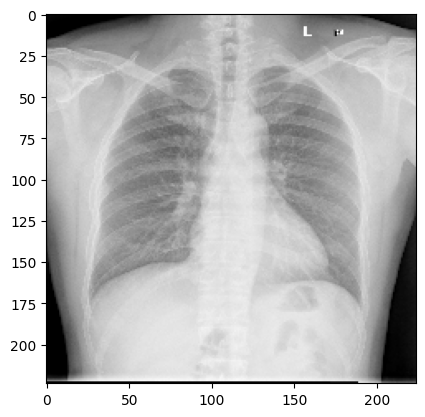

In [36]:
image = x_val[1]
plt.imshow(image)

In [37]:
input_image = np.expand_dims(image, axis=0)  # Agregar una dimensión adicional al principio
print(input_image.shape)

(1, 224, 224, 3)


In [38]:
last_conv_layer = model_hibrid.get_layer("conv_pw_13_relu")
last_conv_layer_model = tf.keras.Model(model_hibrid.inputs, last_conv_layer.output)
classifier_input = tf.keras.Input(shape=last_conv_layer.output.shape[1:])
x = classifier_input
for layer_name in ["global_average_pooling2d", "predictions"]:
    x = model_hibrid.get_layer(layer_name)(x)
classifier_model = tf.keras.Model(classifier_input, x)

In [39]:
grad_model = tf.keras.models.Model(
    [model.inputs], [model.get_layer("conv_pw_13_relu").output, model.get_layer("predictions").output])


with tf.GradientTape() as tape:
    last_conv_layer_output, preds = grad_model(input_image)
    pred_index = tf.argmax(preds[0])
    class_channel = preds[:, pred_index]


grads = tape.gradient(class_channel, last_conv_layer_output)


pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))


last_conv_layer_output = last_conv_layer_output[0]
heatmap = last_conv_layer_output @ pooled_grads[..., tf.newaxis]
heatmap = tf.squeeze(heatmap)



In [40]:
gradcam = np.clip(heatmap, 0, np.max(heatmap)) / np.max(heatmap)
gradcam = cv2.resize(gradcam, (224, 224))

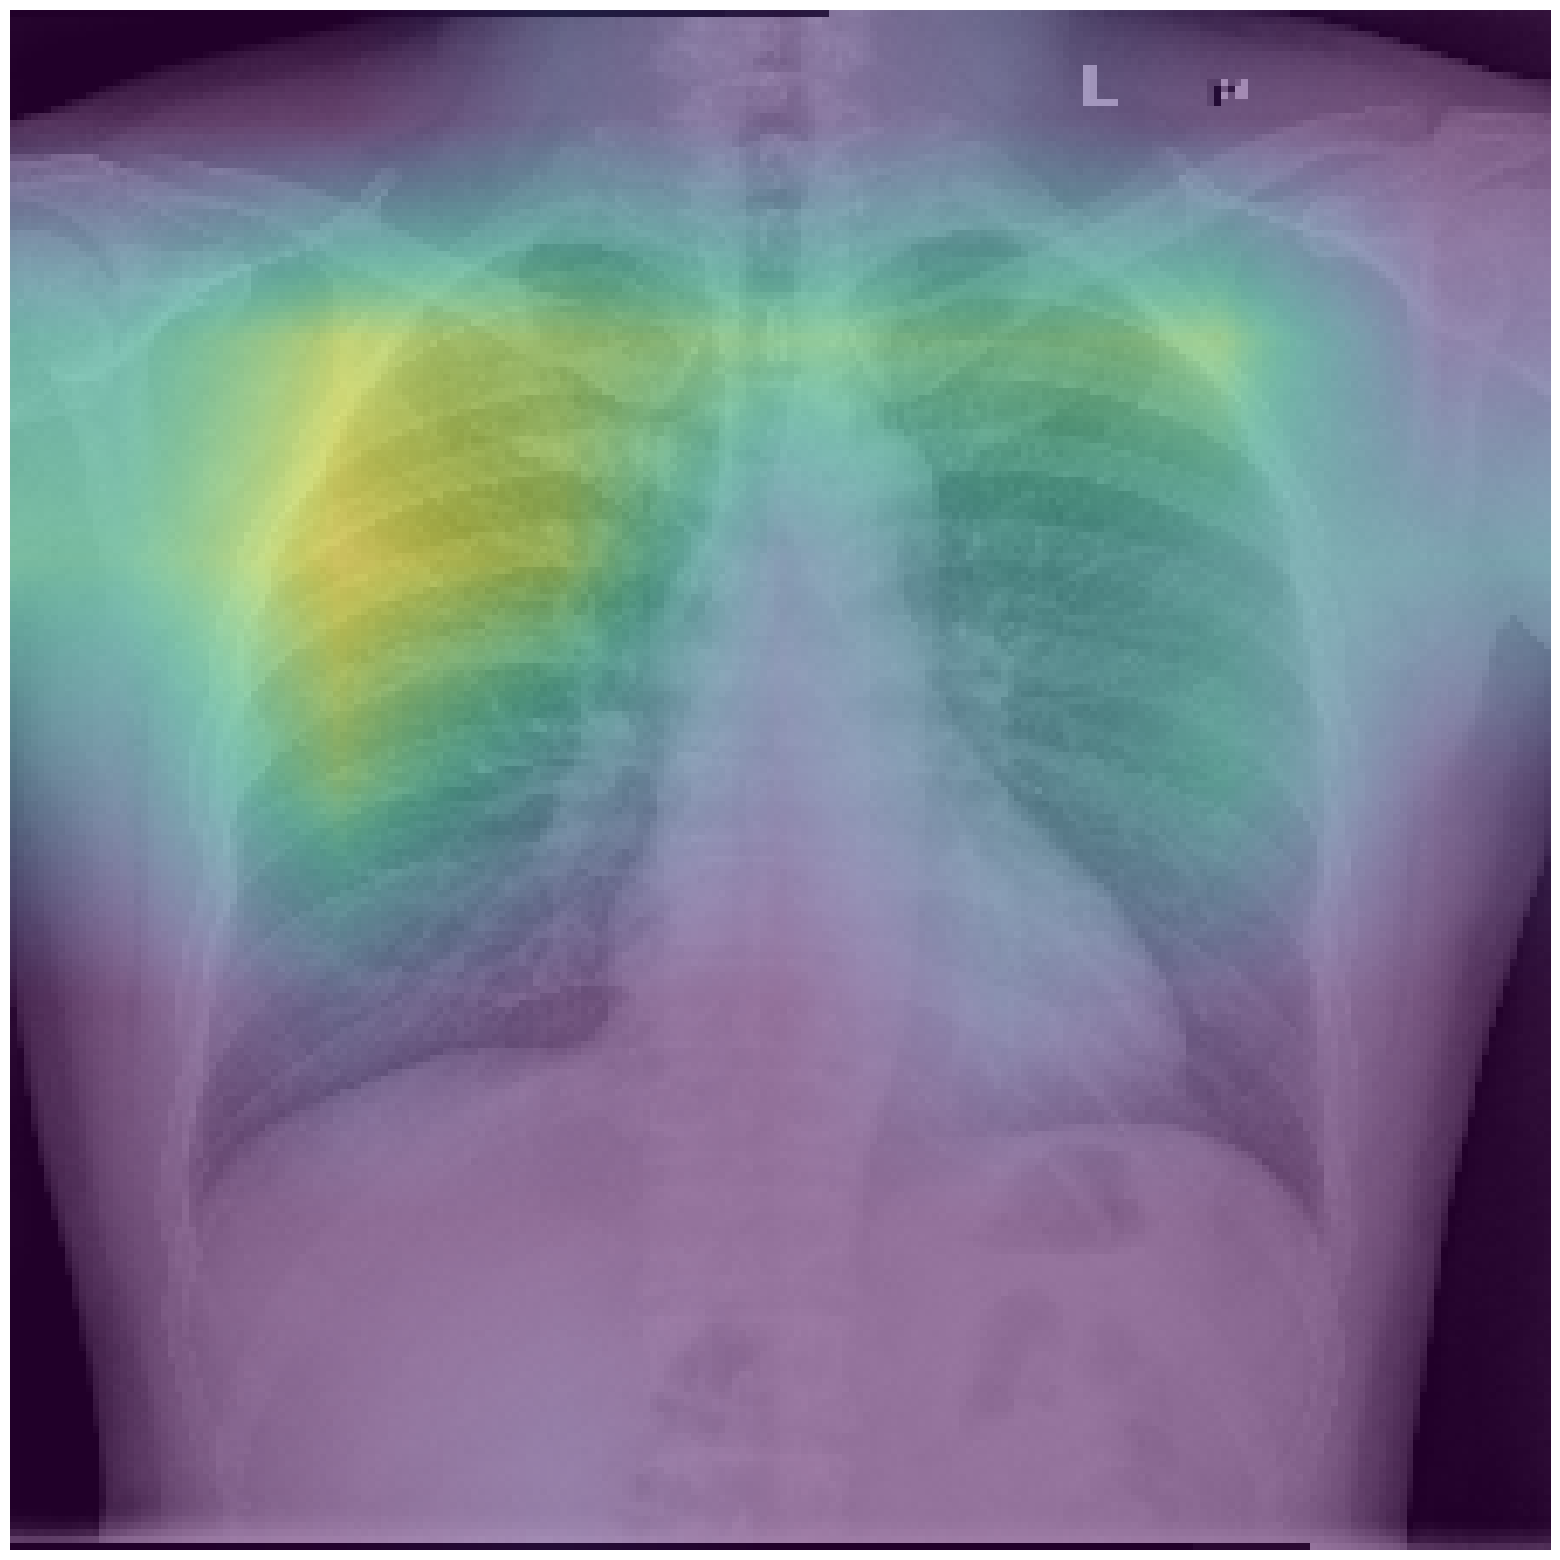

In [47]:
fig = plt.figure(figsize=(45,20))
plt.imshow(image)
plt.imshow(gradcam, alpha=0.5)
plt.axis('off')
plt.savefig('MobileNet_3_task.png')


In [42]:
y_pred=  model_hibrid.predict(x_val)

3/3 [==============================] - 6s 1s/step


In [43]:
y_pred1=  model_hibrid.evaluate(x_test,y_test)

ValueError: in user code:

    File "/opt/conda/lib/python3.10/site-packages/keras/engine/training.py", line 1820, in test_function  *
        return step_function(self, iterator)
    File "/opt/conda/lib/python3.10/site-packages/keras/engine/training.py", line 1804, in step_function  **
        outputs = model.distribute_strategy.run(run_step, args=(data,))
    File "/opt/conda/lib/python3.10/site-packages/keras/engine/training.py", line 1792, in run_step  **
        outputs = model.test_step(data)
    File "/opt/conda/lib/python3.10/site-packages/keras/engine/training.py", line 1758, in test_step
        self.compute_loss(x, y, y_pred, sample_weight)
    File "/opt/conda/lib/python3.10/site-packages/keras/engine/training.py", line 1082, in compute_loss
        return self.compiled_loss(
    File "/opt/conda/lib/python3.10/site-packages/keras/engine/compile_utils.py", line 265, in __call__
        loss_value = loss_obj(y_t, y_p, sample_weight=sw)
    File "/opt/conda/lib/python3.10/si

In [ ]:
plt.imshow(y_pred[2][0])


In [ ]:
for i in range(0,6,3):

        fig = plt.figure(figsize=(25,10))
        
        plt.subplot(2,3,1+i)
        plt.imshow(np.squeeze(x_val[i]),cmap='gray')
        plt.contour(np.squeeze(y_pred[1][i]),[0.8], colors=['red'], linewidths=4)
        plt.contour(np.squeeze(val_masks[i]),[0.8],colors=['green'], linewidths=4)
        
        plt.subplot(2,3,2+i)
        plt.imshow(np.squeeze(x_val[2+i]),cmap='gray')
        plt.contour(np.squeeze(y_pred[1][2+i]),[0.8],colors=['red'], linewidths=4)
        plt.contour(np.squeeze(val_masks[2+i]),[0.8],colors=['green'], linewidths=4)
        
        plt.subplot(2,3,3+i)
        plt.imshow(np.squeeze(x_val[1+i]),cmap='gray')
        plt.contour(np.squeeze(y_pred[1][1+i]),[0.8], colors=['red'], linewidths=4)
        plt.contour(np.squeeze(val_masks[1+i]),[0.8],colors=['green'], linewidths=4)
        
        plt.show()

In [ ]:
import tensorflow as tf
from tensorflow.keras.losses import binary_crossentropy

class MultiTaskLoss(tf.keras.losses.Loss):
    def __init__(self, num_classes=2, class_weights=None):
        super(MultiTaskLoss, self).__init__(name='multitask_loss')
        self.num_classes = num_classes
        
        self.class_weights = [1.0, 1.0]


        # Define trainable weights for each loss function
        if self.class_weights is None:
            self.class_weights = [1.0, 1.0]

        self.dice_weights = tf.Variable([1] * self.num_classes, dtype=tf.float32, trainable=True, name='dice_weights')
        self.bce_weight = tf.Variable(1.0, dtype=tf.float32, trainable=True, name='bce_weight')

    def dice_cf(self, y_true, y_pred):

        dice = dice_coef(y_true, y_pred)
        return dice

    def call(self, y_true, y_pred):
        """Calculate the multi-task loss."""
        # Split y_true and y_pred into classification and segmentation tasks
        y_true_cls, y_true_seg = tf.split(y_true[0]), tf.split(y_true[1]),
        y_pred_cls, y_pred_seg = tf.split(y_pred[0]), f.split(y_pred[1])

        # Calculate the dice coefficient loss for the segmentation task
        dice_loss = 1.0 - tf.reduce_mean(self.dice_coef(y_true_seg, y_pred_seg) * self.dice_weights)

        # Calculate the binary cross-entropy loss for the classification task
        bce_loss = binary_crossentropy(y_true_cls, y_pred_cls)

        # Combine the losses using the trainable weights
        total_loss = (self.dice_weights * dice_loss) + (self.bce_weight * bce_loss)

        return total_loss

In [ ]:
total_loss = MultiTaskLoss()